# 02 · DL walkthrough (Step 5): LSTM forecasting + Autoencoder anomaly detection

Framework: **TensorFlow / Keras** (aapke `RNNipynb.ipynb` jaisa). Final code: `src/dl/lstm_forecast.py`
aur `src/dl/anomaly.py`. Yahan har piece ko alag-alag chalakar dekhte hain.

In [1]:
import sys, os, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)          # so `import src...` works
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 140); plt.rcParams["figure.figsize"] = (11, 4)
print("Project root:", ROOT)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
print("TensorFlow", tf.__version__)

Project root: /home/claude/ai-bi-system


I0000 00:00:1792826658.783962   17490 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792826660.112665   17490 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## Part A — LSTM forecasting

### A1. Data ko "windows" mein todna
LSTM ko sequence chahiye. Har sample = ek region + ek forecast date:
- **input sequence**: pichhle 91 din ki revenue ÷ unka average (level), + day-of-year sin/cos → shape `(91, 3)`
- **aux input**: pichhle saal ke same 30 din (seasonality hint) + region one-hot → shape `(34,)`
- **target**: agle 30 din ÷ level → shape `(30,)`

X_seq (40, 91, 3) | X_aux (40, 34) | y (40, 30)


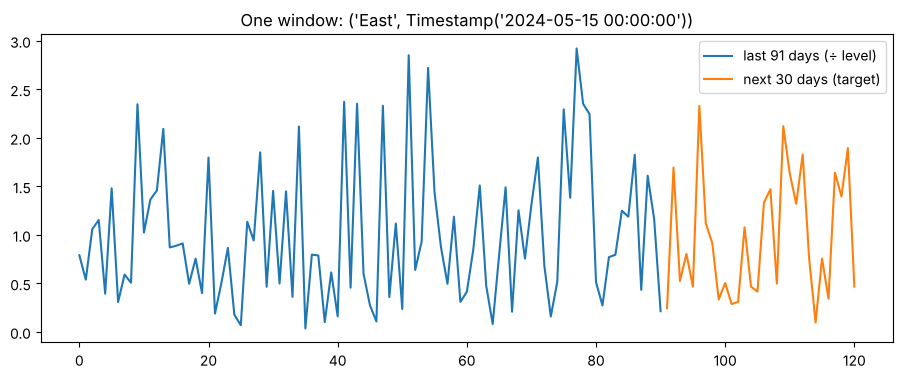

In [2]:
from src.ml.forecasting import load_daily
from src.dl import lstm_forecast as L
daily = load_daily()
Xs, Xa, Y, lv, meta = L.make_windows(daily, list(daily.index[500:510]))
print("X_seq", Xs.shape, "| X_aux", Xa.shape, "| y", Y.shape)
plt.plot(Xs[0, :, 0], label="last 91 days (÷ level)")
plt.plot(range(91, 121), Y[0], label="next 30 days (target)"); plt.legend(); plt.title(f"One window: {meta[0]}"); plt.show()

**Level se divide kyun?** Revenue har saal badhti hai. Bina scaling ke network ne 2026 jaisi badi values
training mein kabhi dekhi hi nahi hoti. Scaling ke baad har window "shape" jaisi dikhti hai.

### A2. Model architecture

In [3]:
model = L.build_model(Xa.shape[1]); model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ history             │ (None, 91, 3)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 48)        │      9,984 │ history[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ last_year_and_regi… │ (None, 34)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 82)        │          0 │ lstm[0][0],       │
│ (Concatenate)       │                   │            │ last_year_and_re… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      5,312 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ next_30_days        │ (None, 30)        │      1,950 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 17,246 (67.37 KB)

 Trainable params: 17,246 (67.37 KB)

 Non-trainable params: 0 (0.00 B)

### A3. Ek fold train karna (festive season: Oct 2025)
Sirf wahi windows train mein jaate hain jinke 30 target din cutoff se pehle khatam ho jaate hain.
`EarlyStopping` validation loss badhna shuru hote hi rok deta hai (overfitting se bachav).

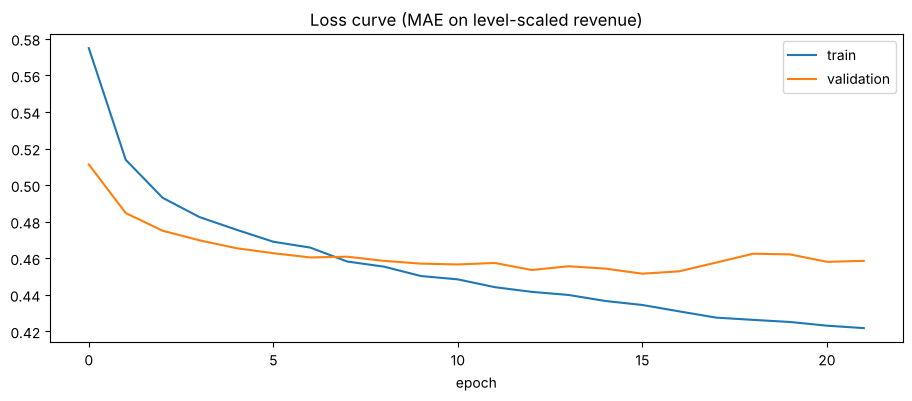

In [4]:
from src.ml.forecasting import fold_cutoffs, backtest_predictions
cutoff = fold_cutoffs(daily)[0]
model, hist = L.train(daily, cutoff)
plt.plot(hist.history["loss"], label="train"); plt.plot(hist.history["val_loss"], label="validation")
plt.legend(); plt.title("Loss curve (MAE on level-scaled revenue)"); plt.xlabel("epoch"); plt.show()

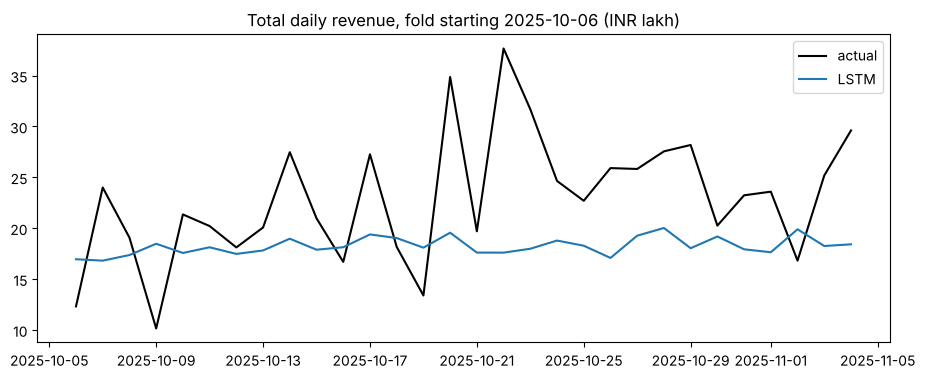

30-day total error: -20.2%


In [5]:
pred = L.predict_from(model, daily, cutoff).groupby("date").pred_lstm.sum()
actual = daily.sum(axis=1).loc[pred.index]
plt.plot(actual.index, actual / 1e5, label="actual", c="k")
plt.plot(pred.index, pred / 1e5, label="LSTM")
plt.legend(); plt.title(f"Total daily revenue, fold starting {cutoff.date()} (INR lakh)"); plt.show()
print(f"30-day total error: {100 * (pred.sum() / actual.sum() - 1):+.1f}%")

### A4. Poora comparison (same 12 folds as Step 3)
Ye `python -m src.dl.lstm_forecast` ka result hai (12 trainings, ~8 min CPU par — isliye notebook mein
dobara nahi chala rahe, report file padh rahe hain):

In [6]:
import json
r = json.load(open("reports/lstm_forecast_metrics.json"))
pd.DataFrame(r["metrics"]).T[["monthly_total_wape", "weekly_total_wape", "weekly_region_wape", "daily_wape"]].sort_values("monthly_total_wape")

,monthly_total_wape,weekly_total_wape,weekly_region_wape,daily_wape
lstm,0.069,0.093,0.175,0.421
ensemble,0.074,0.093,0.169,0.411
gradient_boosting,0.079,0.106,0.178,0.420
naive_last30,0.086,0.104,0.187,0.424
seasonal_naive,0.087,0.132,0.237,0.585


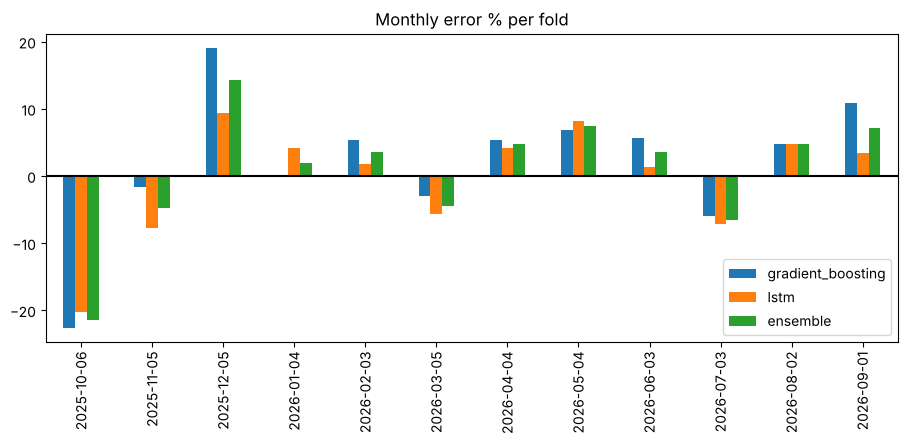

In [7]:
pd.DataFrame(r["monthly_error_pct_by_fold"])[["gradient_boosting", "lstm", "ensemble"]].plot(kind="bar")
plt.axhline(0, c="k"); plt.title("Monthly error % per fold"); plt.show()

### A5. Experiment: MAE loss vs MSE loss
Pehla LSTM `loss="mae"` se train hua tha. Dono runs ka per-fold error dekhiye:

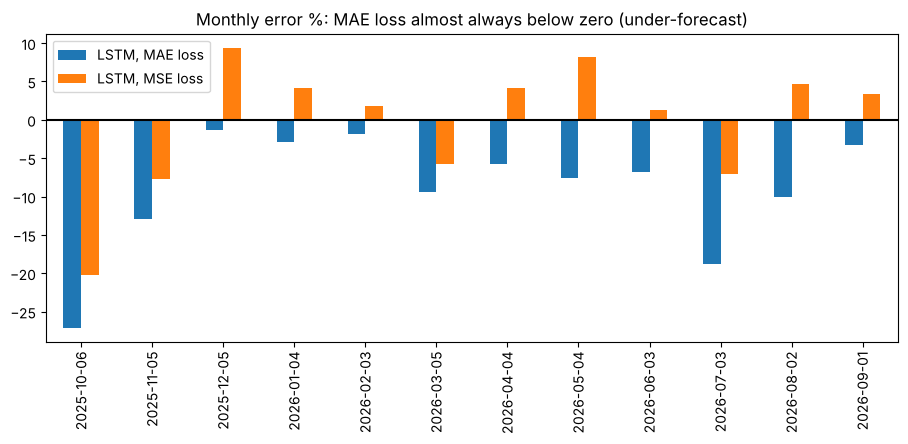

monthly WAPE  MAE: 0.095 | MSE: 0.069


In [8]:
mae = json.load(open("reports/lstm_forecast_metrics_mae.json"))["monthly_error_pct_by_fold"]["lstm"]
mse = r["monthly_error_pct_by_fold"]["lstm"]
pd.DataFrame({"LSTM, MAE loss": mae, "LSTM, MSE loss": mse}).plot(kind="bar")
plt.axhline(0, c="k"); plt.title("Monthly error %: MAE loss almost always below zero (under-forecast)"); plt.show()
print("monthly WAPE  MAE:", json.load(open("reports/lstm_forecast_metrics_mae.json"))["metrics"]["lstm"]["monthly_total_wape"],
      "| MSE:", r["metrics"]["lstm"]["monthly_total_wape"])

## Part B — Autoencoder anomaly detection

### B1. Order features
Har order ko 15 numbers mein badla: revenue/quantity/price (log), discount, *price vs category normal*,
*quantity vs segment normal*, *quantity vs is customer ka normal*, category & segment one-hot.

In [9]:
from src.dl import anomaly as A
orders = A.load_orders()
train = orders[orders.order_date < A.SPLIT_DATE]
ref = A.reference_stats(train)
A.featurize(train, ref).head()

,log_revenue,log_quantity,log_unit_price,discount,price_vs_category,qty_vs_segment,qty_vs_own_history,cat_Electronics,cat_Furniture,cat_Office Supplies,cat_Clothing,seg_Consumer,seg_SMB,seg_Corporate
0,11.238267,1.609438,9.852012,0.00,0.459829,0.000000,0.000000,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,9.701544,0.693147,9.701544,0.00,0.309352,0.000000,0.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,10.419868,1.609438,9.084951,0.05,0.096184,0.000000,0.000000,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,7.644938,1.386294,6.652502,0.10,0.253406,-0.287682,0.000000,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,9.229328,0.693147,9.452452,0.20,0.463720,-1.386294,-1.098612,0.0,1.0,0.0,0.0,0.0,1.0,0.0


### B2. Test set mein jaan-boojh kar gadbad daalna
Real data mein "ye anomaly hai" ka label nahi hota. Isliye 1% fake-bad orders inject karte hain
(price ×10, quantity ×20, 60–90% discount, consumer ka 40 furniture kharidna) aur dekhte hain kitne pakde gaye.

In [10]:
rng = np.random.default_rng(42)
test = A.inject_anomalies(orders[orders.order_date >= A.SPLIT_DATE], rng)
test[test.is_injected == 1][["category", "segment", "quantity", "unit_price", "discount", "anomaly_type"]].head()

,category,segment,quantity,unit_price,discount,anomaly_type
5997,Furniture,SMB,3,629.88,0.00,price_x10
5998,Furniture,Consumer,40,8000.00,0.00,consumer_bulk_furniture
5999,Office Supplies,Consumer,2,1567.50,0.74,huge_discount
6000,Electronics,SMB,60,14015.51,0.00,qty_x20
6001,Electronics,Consumer,60,19191.65,0.15,qty_x20


In [11]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(A.featurize(train, ref))
Xtr = scaler.transform(A.featurize(train, ref)).astype("float32")
Xte = scaler.transform(A.featurize(test, ref)).astype("float32")
tf.keras.utils.set_random_seed(42)
ae = A.build_autoencoder(Xtr.shape[1]); ae.summary()
h = ae.fit(Xtr, Xtr, epochs=30, batch_size=256, validation_split=0.1, verbose=0,
           callbacks=[tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)])
print("epochs trained:", len(h.history["loss"]))

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 14)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 14)             │           238 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 834 (3.26 KB)

 Trainable params: 834 (3.26 KB)

 Non-trainable params: 0 (0.00 B)

epochs trained: 30


Dhyan dijiye: `ae.fit(Xtr, Xtr)` — input aur target **same** hain. Model ko khud ko copy karna hai,
lekin beech mein sirf 4 numbers ka "bottleneck" hai, isliye wo sirf normal patterns yaad rakh pata hai.

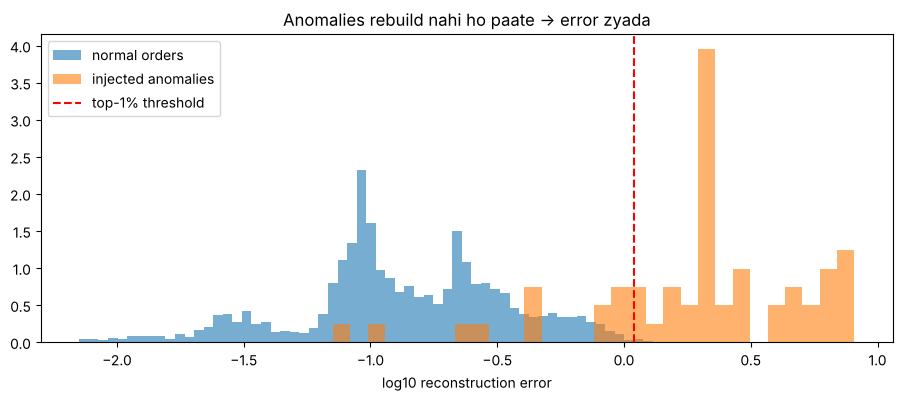

In [12]:
_, err = A.recon_error(ae, Xte)
y = test.is_injected.values
plt.hist(np.log10(err[y == 0]), bins=60, alpha=.6, label="normal orders", density=True)
plt.hist(np.log10(err[y == 1]), bins=30, alpha=.6, label="injected anomalies", density=True)
plt.axvline(np.log10(np.quantile(err, .99)), c="r", ls="--", label="top-1% threshold")
plt.legend(); plt.xlabel("log10 reconstruction error"); plt.title("Anomalies rebuild nahi ho paate → error zyada"); plt.show()

In [13]:
from sklearn.ensemble import IsolationForest
iso = IsolationForest(n_estimators=300, random_state=42).fit(Xtr)
pd.DataFrame({"autoencoder": A.evaluate(y, err), "isolation_forest": A.evaluate(y, -iso.score_samples(Xte))}).T

,roc_auc,pr_auc,precision_in_flagged,recall_in_flagged
autoencoder,0.962,0.841,0.783,0.797
isolation_forest,0.909,0.371,0.433,0.441


### B3. Real orders jo flag hue

In [14]:
pd.read_csv("data/processed/order_anomalies.csv").head(10)

,order_id,order_date,customer_id,region,category,quantity,unit_price,discount,revenue,segment,anomaly_score,main_reason
0,O0057092,2026-03-22,C01679,East,Electronics,1,8503.16,0.20,6802.53,Corporate,4.473,qty_vs_own_history
1,O0019725,2024-06-30,C02317,South,Furniture,2,2873.69,0.00,5747.38,Corporate,1.915,qty_vs_own_history
2,O0047434,2025-11-03,C01471,South,Office Supplies,1,4597.41,0.20,3677.93,Consumer,1.711,price_vs_category
3,O0006861,2023-08-29,C00588,South,Office Supplies,2,115.97,0.10,208.75,Corporate,1.669,qty_vs_own_history
4,O0000461,2023-01-19,C01209,North,Office Supplies,1,4226.81,0.00,4226.81,Consumer,1.484,price_vs_category
5,O0003395,2023-05-04,C01671,South,Electronics,3,6768.10,0.20,16243.44,Corporate,1.466,qty_vs_own_history
6,O0000301,2023-01-13,C00676,South,Office Supplies,1,4134.78,0.15,3514.56,Consumer,1.463,price_vs_category
7,O0034245,2025-03-29,C02725,West,Office Supplies,1,3647.52,0.00,3647.52,Consumer,1.457,price_vs_category
8,O0044704,2025-09-30,C01261,North,Clothing,3,1386.88,0.10,3744.58,Corporate,1.452,qty_vs_own_history
9,O0032136,2025-02-18,C02739,South,Furniture,1,23075.62,0.05,21921.84,SMB,1.451,qty_vs_own_history


## Takeaways
- **Loss function = model kya predict karega.** MAE loss median deta hai → revenue jaisi skewed cheez par
  har mahine kam forecast (9.5% error). MSE loss mean deta hai → 6.9%. Wahi galti jo Step 3 mein log-target se hui thi.
- Fix ke baad LSTM is data par sabse accha single model nikla (6.9% vs gradient boosting 7.9%).
  Lekin ye hamesha nahi hota — chhote tabular data par tree models aksar jeet-te hain. Isliye **har baar same
  test par compare karo**, maan ke mat chalo.
- **Autoencoder** bina labels ke "normal" seekh kar unusual orders pakad leta hai — Isolation Forest se kaafi behtar.